# unibo-dfm-x-py
End-to-end pipeline: FRED-QD data preparation, static factor analysis, dynamic factor model estimation and rolling-window forecasting. This notebook mirrors `main.py`.

In [1]:
import scipy
from scipy.stats import chi2
import numpy as np
import pandas as pd
import sys
sys.path.insert(-1, './src/')

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from src.modules.ABC_crit import ABC_crit
from src.modules.Fred_transform import Fred_transform
from src.utils.impute import impute_missing
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss

In [3]:
plt.rc('figure', figsize=(16,6))
sns.set_style('darkgrid')

In [4]:
## Define default seed
seed = 1776

## 1. Load and initialize the data.

Data source is FredQD Quarterly data base.

In [5]:
## Load data and apply fred transforms
df = pd.read_csv('./data/2026-04-QD.csv')
## Often for some variables the observation corresponding to the last observation date is not yet recorded
df = df.iloc[:-1,:]
fred_df = Fred_transform(df, freq='QD')
fred_df.index.freq = fred_df.index.inferred_freq

In [6]:
## The first two observations will be lost due to the stationary I(2) transforms
fred_df = fred_df.iloc[2:,:]

In [7]:
## Choose how to handle missing data
ls_missing = fred_df.isna().any()
ls_missing = ls_missing.loc[ls_missing == True]
ls_missing.shape

(37,)

In [8]:
series_init = dict()

In [9]:
## To get a sense of the starting date for each series
for key, _ in ls_missing.items():
    fr_index = fred_df[key].first_valid_index()
    series_init[key] = fr_index

In [10]:
fred_df.loc[fred_df.isna().any(axis=1), fred_df.isna().any(axis=0)]

## Starting dates vary from one variable to another
## To eliminate the NaNs from the data set, we can move the starting date to a future point in time
## and then remove the remaining columns for which the data set still contains missing values.
## Setting the starting point to 1971Q3 and then removing the remaining columns with NaNs seems to be a good compromise.

,OUTMS,TCU,LNS13023621,LNS13023557,LNS13023705,LNS13023569,HOAMS,AWHNONAG,PERMIT,ACOGNOx,...,UMCSENTx,USEPUINDXM,GFDEGDQ188S,GFDEBTNx,PERMITNE,PERMITMW,PERMITS,PERMITW,NASDAQCOM,CUSR0000SEHC
sasdate,,,,,,,,,,,,,,,,,,,,,
1959-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959-12-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,93.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-03-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1960-06-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.035388,NaN,...,93.3,NaN,NaN,NaN,-0.089273,-0.001434,-0.040410,-0.019418,NaN,NaN
1960-09-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.016326,NaN,...,97.2,NaN,NaN,NaN,0.070464,-0.033555,-0.084827,0.002304,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1999-03-01,0.012321,82.0920,-0.044996,-0.035793,0.052728,-0.049651,-0.010575,-0.0667,-0.003122,0.024702,...,105.9,-15.7348,-0.35802,36822.5,-0.032790,-0.059348,0.039118,-0.021421,0.243688,-0.001978
1999-06-01,0.009770,81.9329,-0.009097,-0.010064,0.077738,-0.121642,-0.003738,-0.0333,-0.034798,0.004440,...,106.2,-13.1322,-0.85667,-62644.3,-0.017805,0.011765,-0.076143,-0.004823,0.062884,-0.000035
1999-09-01,0.005179,81.7611,-0.015264,-0.009831,-0.028077,0.079228,0.004106,0.0000,-0.007719,0.012656,...,105.9,3.8499,-0.79969,-18744.6,-0.038662,-0.008811,0.020488,-0.045331,0.078176,-0.000035


In [11]:
fred_df = fred_df.loc['1971-06-01':,:]
fred_df = fred_df.dropna(axis=1)

In [12]:
## Some series are still non-stationary even after transformations
## Need to identify and analyze
nonstat_names = []
for c in fred_df.columns:
    ## Tests are run on series up to 2019 to exclude COVID19 shocks
    adf_pval = adfuller(fred_df[c].loc[:'2019'], autolag='AIC', maxlag=8,regression='c')[1]
    if adf_pval > 0.05:
        nonstat_names.append(c)

In [13]:
'''
['USEHS',
 'USSERV',
 'CES9092000001',
 'CIVPART',
 'GS1TB3Mx',
 'NWPIx',
 'GFDEBTNx',
 'TLBSNNBBDIx']

These are the series that do not pass the Dickey Fuller test with constant regression.
Each series has to be individually analyzed via other tests such as kpss, acf, Taylor-Cavaliere, ecc.
'''

## 1. Non stationarity of USEHS is obviously due to a structural break in the late 90s.
## 2. USSERV seems to have a unit root.
## 3. CES9092000001 seems to have a unit root.
## 4. CIVPART is not a unit root process but it isn't stationary either as it does not pass the kpss test under any circumstances.
## 5. GS1TB3Mx is evidently not stationary, it is enough too look at its plot over time.
## 6. NWPIx is trend stationary.
## 7. GFDEBTNx is super non stationary. It is obvious that its variance doesn't exist.
## 8. TLBSNNBBDIx is also non stationary.

"\n['USEHS',\n 'USSERV',\n 'CES9092000001',\n 'CIVPART',\n 'GS1TB3Mx',\n 'NWPIx',\n 'GFDEBTNx',\n 'TLBSNNBBDIx']\n\nThese are the series that do not pass the Dickey Fuller test with constant regression.\nEach series has to be individually analyzed via other tests such as kpss, acf, Taylor-Cavaliere, ecc.\n"

In [14]:
## Thus, we will keep USEHS and de-trend NWPIx. The rest of the series will be dropped.
nonstat_names.remove('USEHS')
nonstat_names.remove('NWPIx')
fred_df = fred_df.drop(columns=nonstat_names)

<Axes: xlabel='sasdate'>

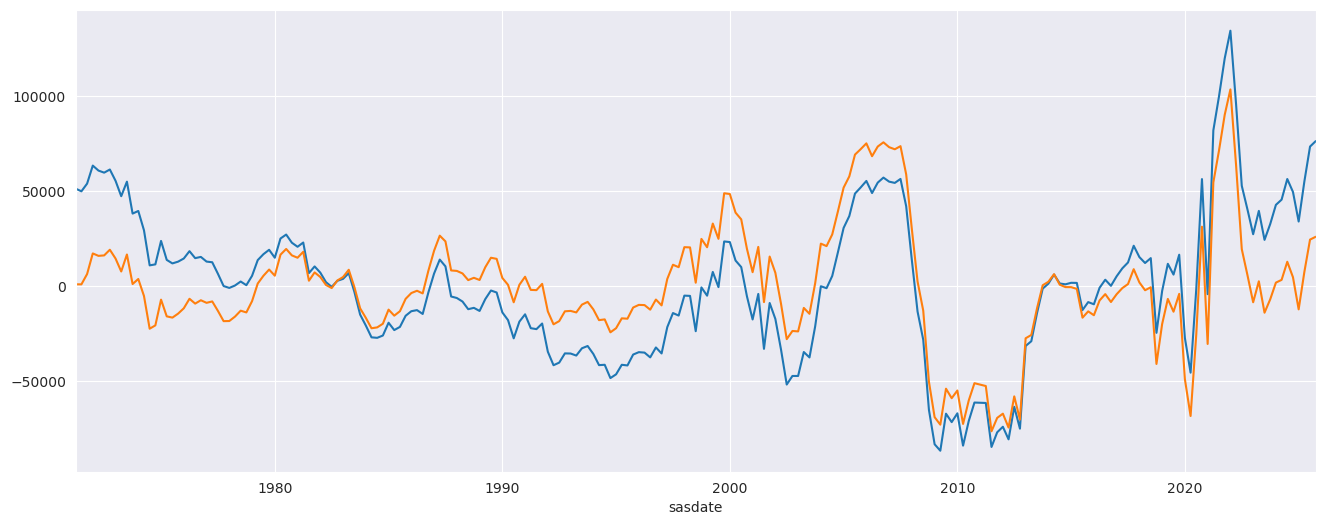

In [15]:
## Detrending NWPIx
sm.tsa.tsatools.detrend(fred_df['NWPIx'], order=1).plot()
sm.tsa.tsatools.detrend(fred_df['NWPIx'], order=2).plot()

In [16]:
## quadratic detrending yields smoother results
fred_df['NWPIx'] = sm.tsa.tsatools.detrend(fred_df['NWPIx'], order=2)

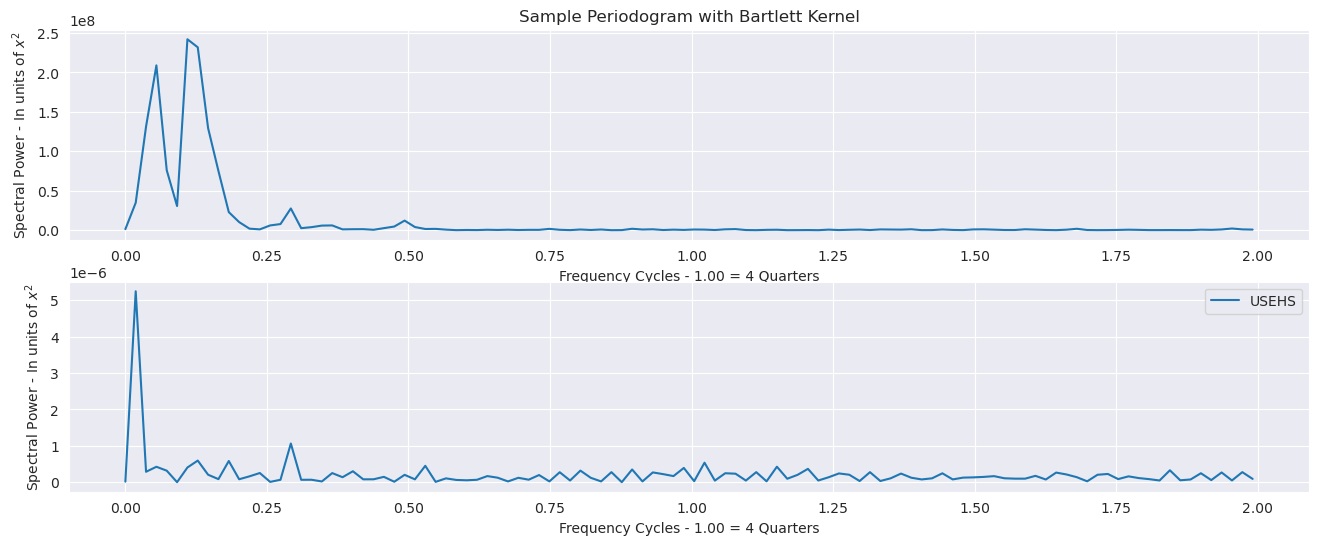

In [17]:
## Conviene stimare anche lo spettro di queste serie per valutare l'importanza dei diversi cicli
fxx1, pxx_spec_NWPIx = scipy.signal.periodogram(fred_df['NWPIx'], fs=4, window='bartlett', scaling='spectrum')
fxx2, pxx_spec_USEHS = scipy.signal.periodogram(fred_df['USEHS'], fs=4, window='bartlett', scaling='spectrum')
fig, ax = plt.subplots(nrows=2)
ax[0].plot(fxx1, pxx_spec_NWPIx, label='NWPIx')
ax[0].set_xlabel('Frequency Cycles - 1.00 = 4 Quarters')
ax[0].set_ylabel('Spectral Power - In units of $x^2$')
ax[0].set_title('Sample Periodogram with Bartlett Kernel')
ax[0].legend

ax[1].plot(fxx2, pxx_spec_USEHS, label='USEHS')
ax[1].set_xlabel('Frequency Cycles - 1.00 = 4 Quarters')
ax[1].set_ylabel('Spectral Power - In units of $x^2$')
ax[1].legend()
plt.show()

In [18]:
ax[1].plot(fxx2, pxx_spec_USEHS, label='USEHS')
ax[1].set_xlabel('Frequency Cycles - 1.00 = 4 Quarters')
ax[1].set_ylabel('Spectral Power - In units of $x^2$')
ax[1].legend()
plt.show()

## seems like the low frequency components are very dominant even after detrending, thus
## it's best to remove these series as well

In [19]:
fred_df = fred_df.drop(columns=['NWPIx','USEHS'])

In [20]:
## Need to handle COVID period. Typically 2020Q2 and 2020Q3 are set to NaN and later imputed with the Kalman smoother.
fred_df.loc['2020-06-01':'2020-09-01',:] = None

In [21]:
## Make a copy of the full dataset and then truncate it to include only the first 80 observations for 
## the pre-estimation analysis. This window size corresponds to 20 years of quarterly data which is standard practice in the literature.
W = 80
fred_df_full = fred_df.copy(deep=True)
fred_df = fred_df.iloc[:W]

## 2. Factor Analysis via Static Methods

2.1 Estiamte the number of common factors via the ABC criterion.
2.2 Obtain estimates of the loadings and the factors via PCA and linear projection under the identification scheme:
    (F.T @ F)/T = I_r
2.3 Idnetify the matrix of loadings by fixing the sign of the first row to be positive
2.4 Obtain residuals and compute their sample variances
2.5 AIC + Likelihood Ratio test for determining the order of the VAR process followed by the common factors.

In [22]:
T, n = fred_df.shape
## Bai and Ng (2002) upper bound for kmax
kf = int((min(n,T)/100)**0.25)
kmax = 8 * kf if kf > 0 else 8

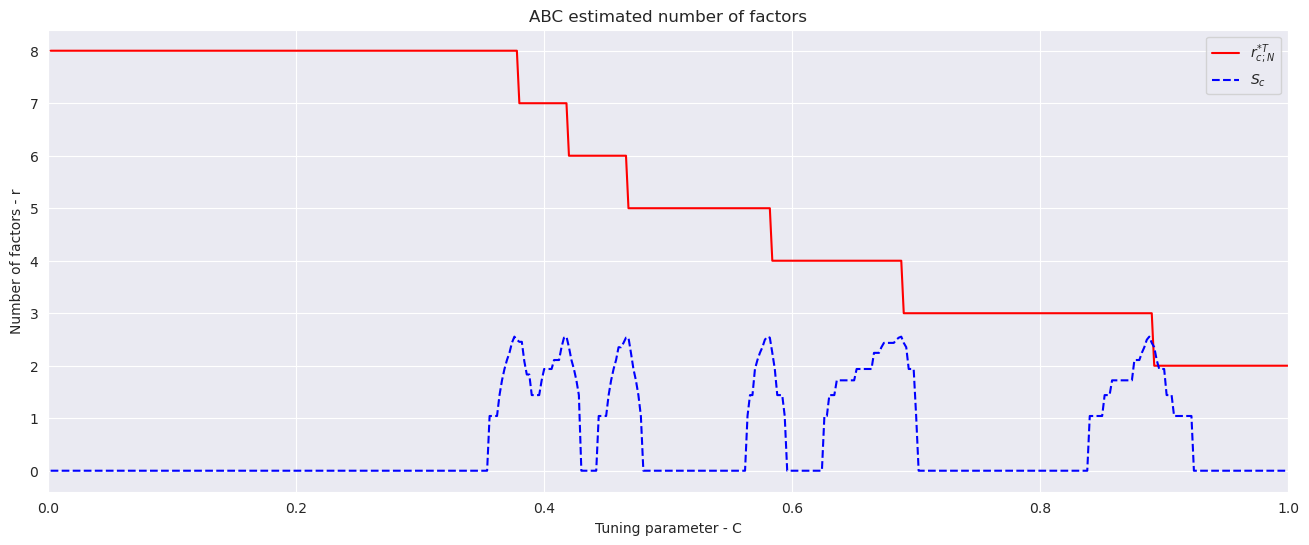

In [23]:
fig, ax = plt.subplots()
rhat1, rhat2, plot = ABC_crit(fred_df, kmax, seed=seed, ax=ax, standardize=True)
plt.show()

In [24]:
## rhat1 and rhat2 are the estimated number of common factors at 5 and 1 percent thresholds.
kfactors = rhat1

In [25]:
from src.models.static_methods import SFM_StateSpace
from src.models.dynamic_methods import DynamicFM

## 2. Factor Analysis via Static Methods

2.1 Obtain estimates of the loadings and the factors via PCA and linear projection under the identification scheme:
    (F.T @ F)/T = I_r
    with the loadings of the first variable fixed to be positive.
2.2 Obtain residuals and compute their sample variances
2.3 AIC + Likelihood Ratio test for determining the order of the VAR process followed by the common factors.

In [26]:
## Standardization, PCA via SVD and the identification of the factors and the loadings are all handled by SFM_StateSpace.
## The derivations of the identification scheme are in playground.py and static_methods.py
sfm = SFM_StateSpace(fred_df, nfactors=kfactors, standardize=True, method='svd',
                     missing='fill-em', normalize=True)

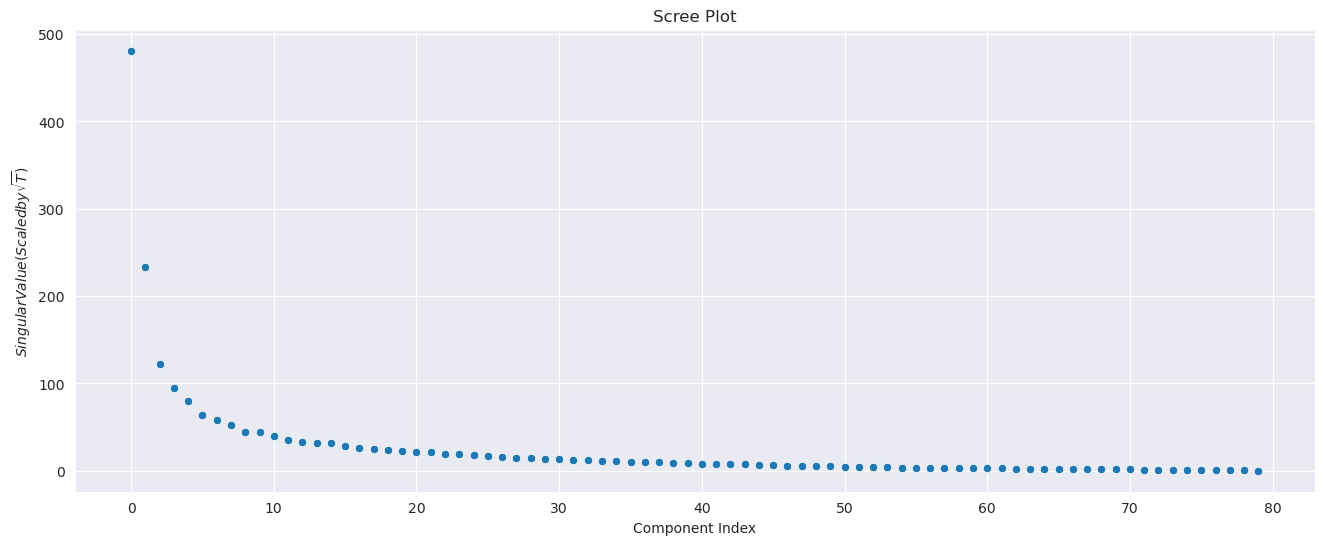

In [27]:
## Visualize the scree plot
sfm.plot_scree()
plt.show()

In [28]:
F_hat = sfm.factors
Lambda_hat = sfm.loadings
resid = sfm.standardized_residuals
## estimated variance of the residuals, this will be later fed into the EM algorithm in the initialization step
resid_var = resid.std()**2

In [29]:
## Specify a VAR process for the estiamted factors and use AIC to select the lag order of the process
## The upper bound is set to one year of quarterly lags. With maxlags=8, AIC always picks 8, and a VAR(8) for 5 factors on a window of 80 observations
## makes the EM algorithm fail on some of the windows (non positive definite covariance of the factor innovations)
state_var = sm.tsa.VAR(F_hat, freq=F_hat.index.freq)
state_lag_res = state_var.select_order(maxlags=4, trend='n')
lag_aic = state_lag_res.aic

/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)


In [30]:
## We now compare the AIC selected process with the next most parsimonious process (whose order is simply given by the AIC selected lag order minus one) via the likelihood ratio test
if lag_aic <= 1:
    state_lag = lag_aic
else:
    fit1 = sm.tsa.VAR(F_hat, freq=F_hat.index.freq).fit(maxlags=lag_aic, ic=None, trend='n')
    fit2 = sm.tsa.VAR(F_hat.iloc[1:,:], freq=F_hat.index.freq).fit(maxlags=lag_aic-1, ic=None, trend='n')
    lr_stat = -2 * (fit2.llf - fit1.llf)
    chi_df = F_hat.shape[1] ** 2

    lr_pval = chi2.sf(lr_stat, chi_df)

    state_lag = lag_aic if lr_pval < 0.05 else lag_aic - 1

/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)
/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)


## 3. State Space Representation and Estimation of the DFM

3.1 Fix a window size for the rolling-window estimation and forecasting scheme
3.2 Initialize the estimation procedure with the PCA estimates of the model parameters
3.3 At each iteration produce 1 step ahead and 4 step ahead forecasts of the individual series and obtain forecast losses

In [31]:
## Estimate on the first window, the starting parameters are the PCA estimates obtained above
## (DynamicFM repeats the static initialization internally on the window it is given)
dfm = DynamicFM(fred_df, nfactors=kfactors, factor_orders=state_lag, idiosyncratic_ar1=False)
dfm_res = dfm.results
print(dfm_res.summary())

/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)


                               Dynamic Factor Results                              
Dep. Variable:       "GDPC1", and 221 more   No. Observations:                   80
Model:                Dynamic Factor Model   Log Likelihood              -17681.931
                   + 5 factors in 1 blocks   AIC                          38257.861
                       + iid idiosyncratic   BIC                          41704.654
Date:                     Thu, 29 Oct 2026   HQIC                         39639.779
Time:                             00:35:05   EM Iterations                      155
Sample:                         06-01-1971                                         
                              - 03-01-1991                                         
Covariance Type:              Not computed                                         
                               Observation equation:                                
Factor loadings:        0.1        0.2        0.3         0.4         0.5  

## 4. Post-Estimation Analysis and Diagnostic Tests

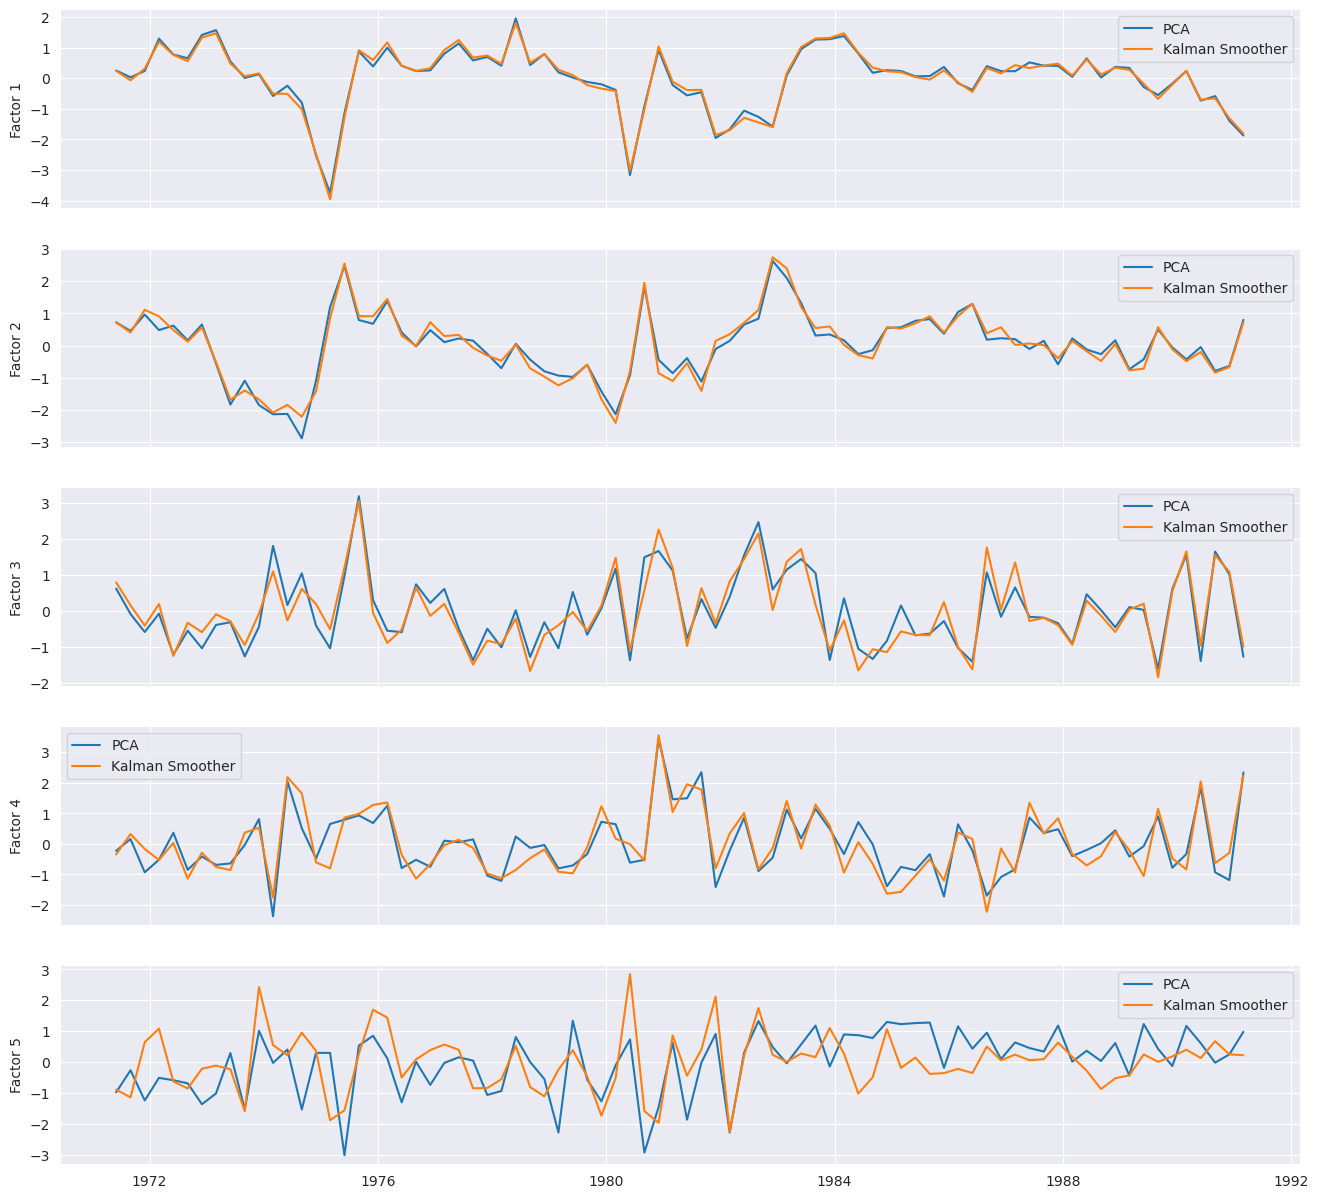

In [32]:
## Compare the principle components with the smoothed states from the Kalman Smoother
fig, ax = plt.subplots(nrows=kfactors, sharex=True, figsize=(16, 3*kfactors))
ax = np.atleast_1d(ax)
for k in range(kfactors):
    ax[k].plot(F_hat.index, F_hat.iloc[:,k], label='PCA')
    ax[k].plot(F_hat.index, dfm_res.factors.smoothed.iloc[:,k].to_numpy(), label='Kalman Smoother')
    ax[k].set_ylabel(f'Factor {k+1}')
    ax[k].legend()
plt.show()

## 4.1 Spectral Analysis

Periodograms of the estimated common factors via DFM_periodogram.

In [33]:
from src.modules.DFM_periodogram import DFM_periodogram

In [34]:
## Select variables for producing and comparing forecasts
series_names = [c for c in ['GDPC1', 'PCECC96', 'UNRATE', 'DPIC96', 'INDPRO', 'HOUST', 'TB3MS'] if c in fred_df.columns]

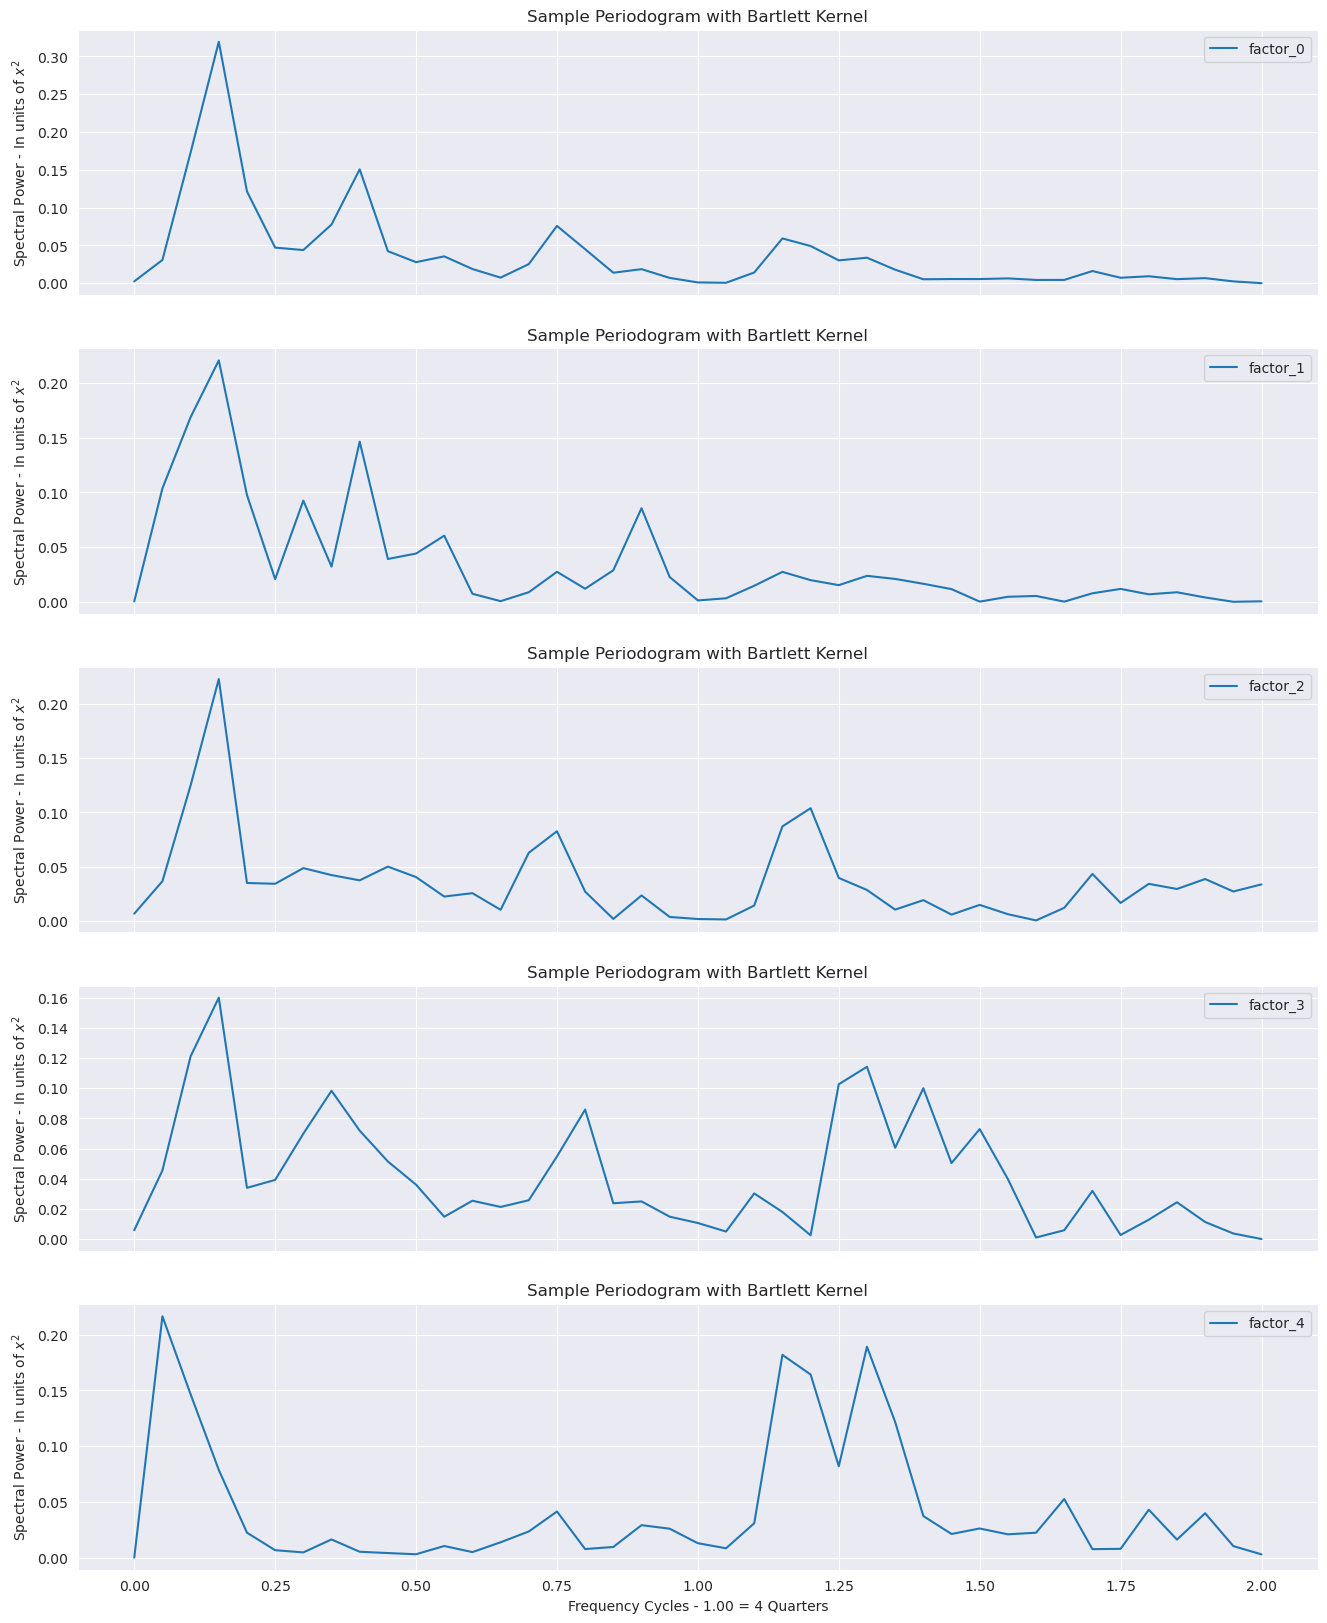

In [35]:
## Spectrum of the estimated common factors estimated by the periodogram
fig, ax = plt.subplots(nrows=kfactors, sharex=True, figsize=(16, 4*kfactors))
ax = np.atleast_1d(ax)
for k in range(kfactors):
    DFM_periodogram(F_hat.iloc[:,k], freq='QD', ax=ax[k])
    if k < kfactors - 1:
        ax[k].set_xlabel('')
plt.show()

## 5. Forecasting via The Common Component

Rolling window of fixed size W. At each origin the model is re-estimated, and the forecasts, which are
produced on the standardized scale, are brought back to the original scale via the moments of the window.

In [36]:
## Forecast horizons
horizons = [1, 4]
H = max(horizons)

In [37]:
T_full = fred_df_full.shape[0]
origins = range(W, T_full - H + 1)

In [38]:
fc_dfm = {h: [] for h in horizons}
actual = {h: [] for h in horizons}
fc_index = {h: [] for h in horizons}

In [39]:
## Cap on the number of EM iterations when the model is re-estimated at each forecast origin. Starting from the PCA estimates,
## a full run of 500 iterations on every window is prohibitively slow
maxiter_roll = 50

In [40]:
for origin in origins:
    window = fred_df_full.iloc[origin-W:origin,:]
    window.index.freq = window.index.inferred_freq
    dfm_w = DynamicFM(window, nfactors=kfactors, factor_orders=state_lag, maxiter=maxiter_roll)
    fc = dfm_w.results.forecast(steps=H)
    fc = fc * dfm_w.sigma + dfm_w.mu
    for h in horizons:
        fc_dfm[h].append(fc.iloc[h-1,:].to_numpy())
        actual[h].append(fred_df_full.iloc[origin+h-1,:].to_numpy())
        fc_index[h].append(fred_df_full.index[origin+h-1])

/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)
/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/statespace/dynamic_factor_mq.py:2695: UserWarning: EM reached maximum number of iterations (50), without achieving convergence: llf=-17690, convergence criterion=2.4586e-05 (while specified tolerance was 1e-06)
  warn(f'EM reached maximum number of iterations ({maxiter}),'
/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-DEC will be used.
  self._init_dates(dates, freq)
/home/tl/anaconda3/envs/valhalla/lib/python3.12/site-packages/statsmodels/tsa/statespace/dynamic_factor_mq.py:2695: UserWarning: EM reached maximum number of iterations (50), without achievi

In [41]:
## Collect the forecasts of each horizon in a dataframe indexed by the date of the target observation
fc_df = {h: pd.DataFrame(np.array(fc_dfm[h]), index=fc_index[h], columns=fred_df_full.columns) for h in horizons}

In [42]:
## Mean squared forecast errors of the select variables, one column per forecast horizon
## The errors are on the scale of the transformed data. The COVID quarters are missing in the observations and are therefore skipped in the averages
msfe = pd.DataFrame({f'h = {h}': ((fred_df_full.loc[fc_df[h].index, series_names] - fc_df[h][series_names])**2).mean()
                     for h in horizons})
msfe.index.name = 'MSFE'
print(msfe)

            h = 1     h = 4
MSFE                       
GDPC1    0.000035  0.000043
PCECC96  0.000027  0.000039
UNRATE   0.081439  0.113140
DPIC96   0.000240  0.000249
INDPRO   0.000105  0.000190
HOUST    0.005434  0.005624
TB3MS    0.199467  0.239885


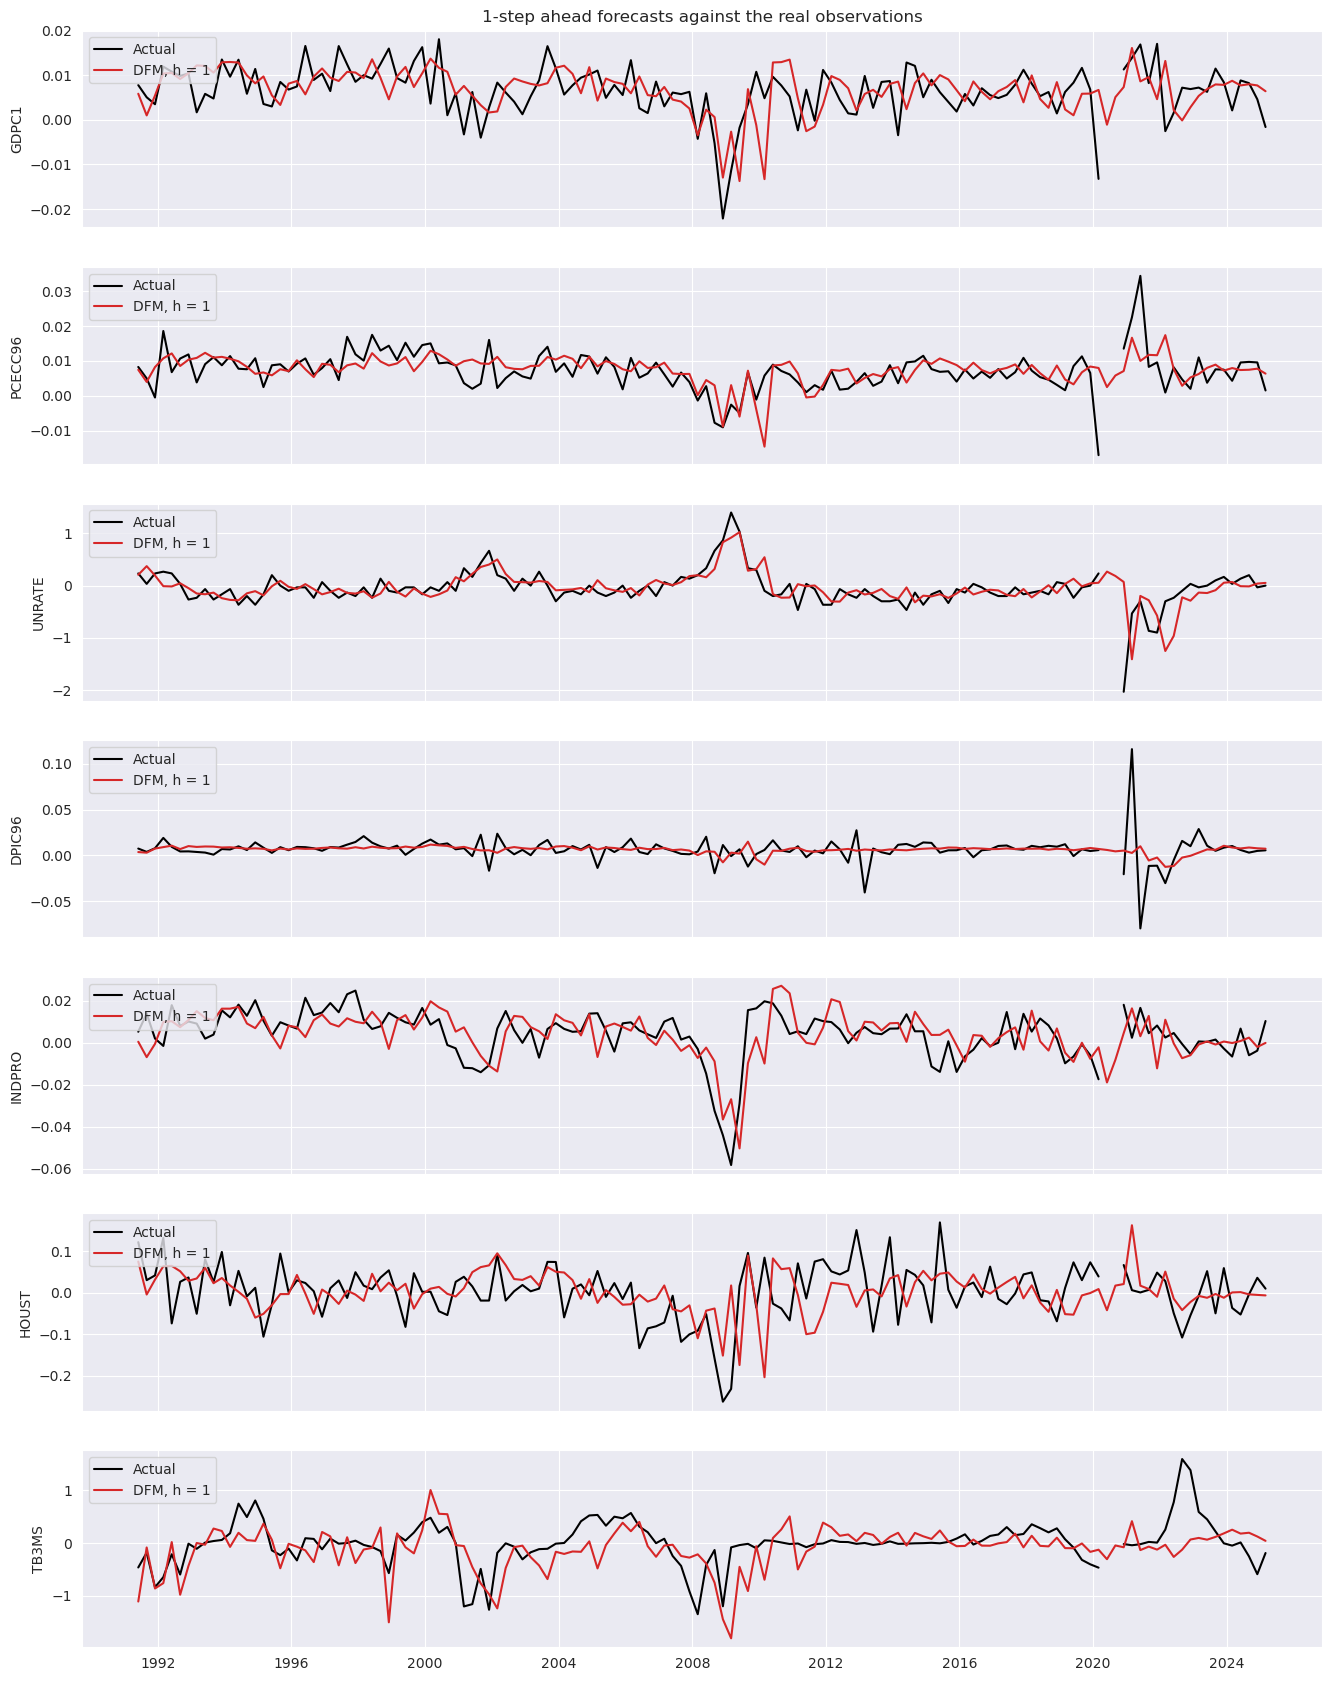

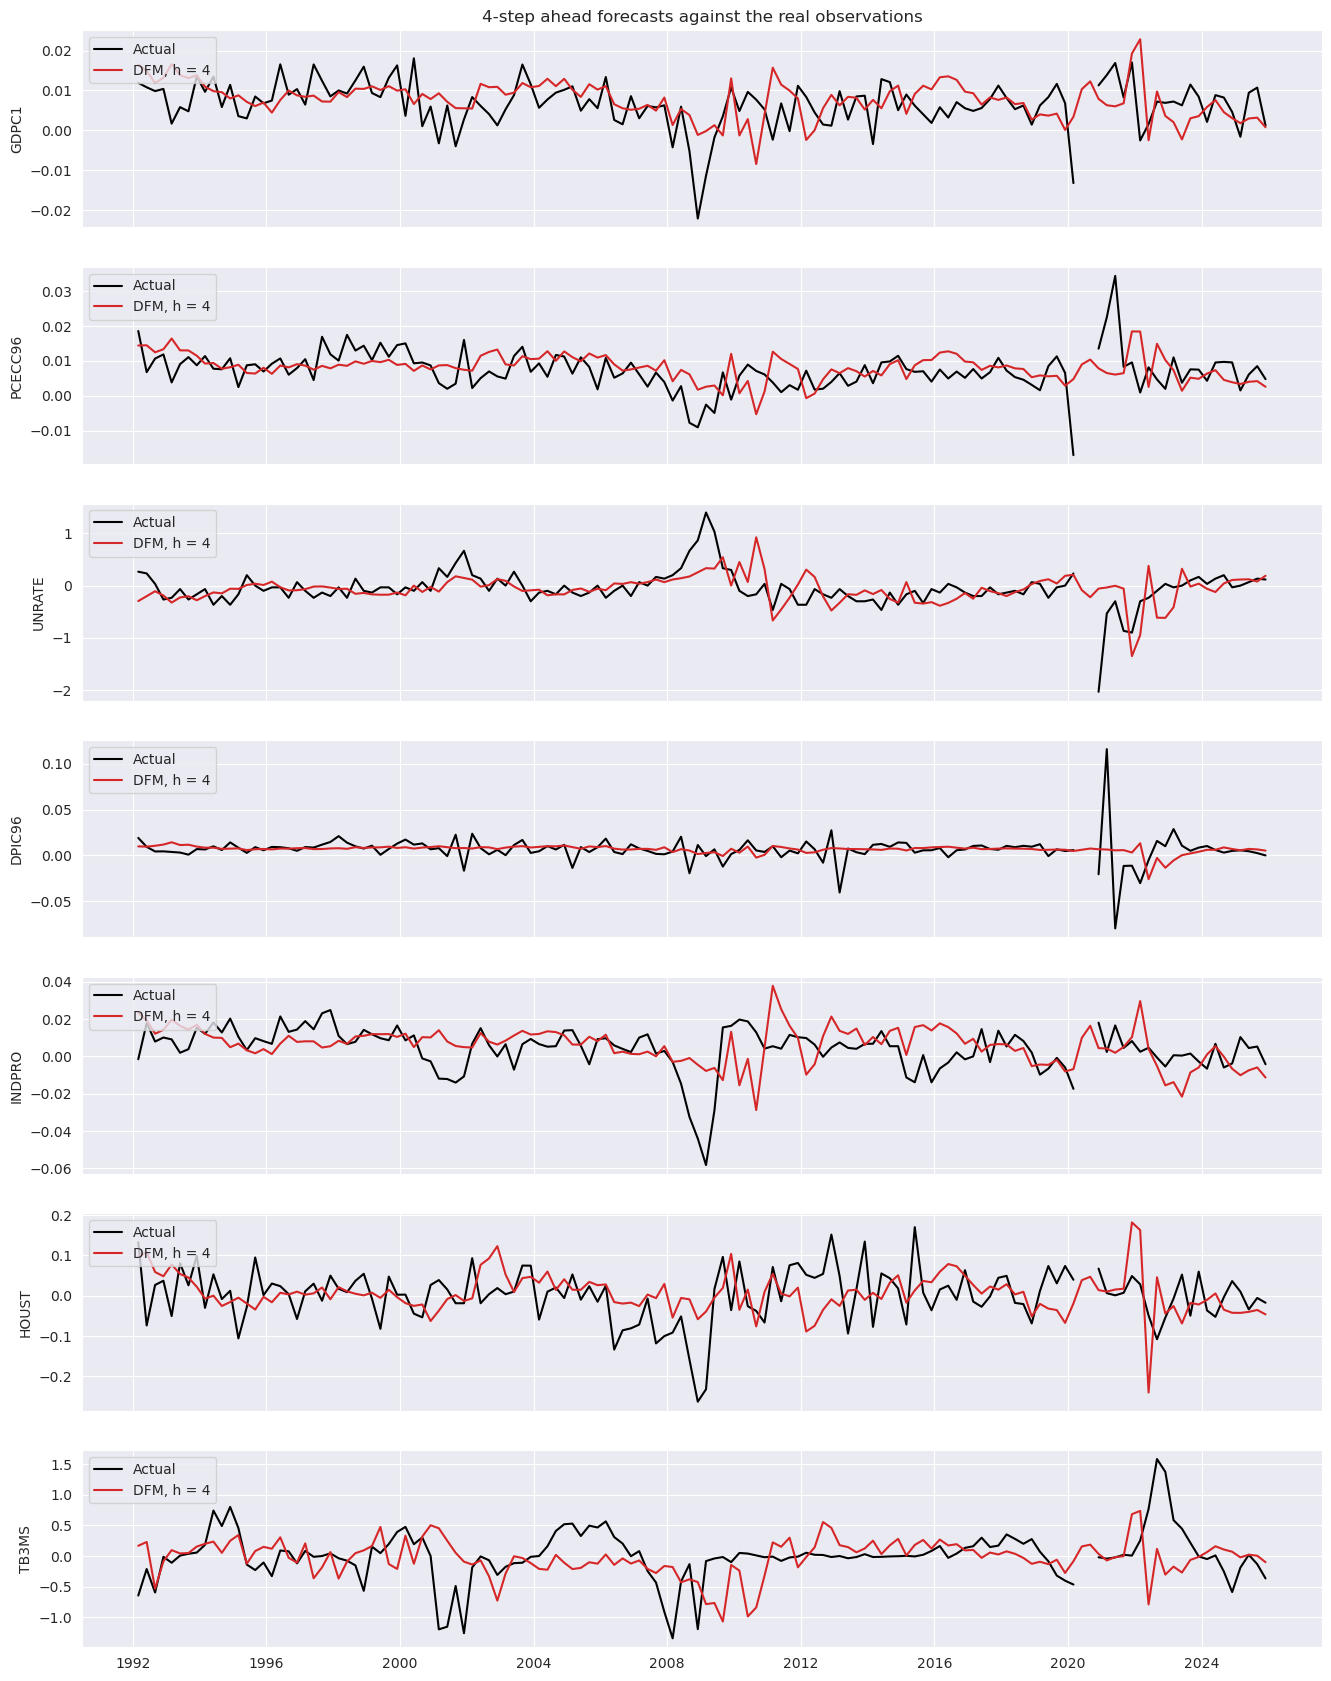

In [43]:
## Visualize the forecasts against the real observations for the select variables
for h in horizons:
    fig, ax = plt.subplots(nrows=len(series_names), sharex=True, figsize=(16, 3*len(series_names)))
    ax = np.atleast_1d(ax)
    for i, name in enumerate(series_names):
        ax[i].plot(fred_df_full[name].loc[fc_df[h].index], color='k', label='Actual')
        ax[i].plot(fc_df[h][name], color='C3', label=f'DFM, h = {h}')
        ax[i].set_ylabel(name)
        ax[i].legend(loc='upper left')
    ax[0].set_title(f'{h}-step ahead forecasts against the real observations')
    plt.show()